# EIA Inventory Impact - Exploratory Data Analysis
This notebook performs a comprehensive exploratory analysis on the EIA master dataset to determine
how inventory changes impact WTI prices across different market regimes and seasons.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os

# Create output directories
out_dir = Path("eia_dataset")
plot_dir = out_dir / "plots"
analysis_dir = out_dir / "analysis"
plot_dir.mkdir(exist_ok=True, parents=True)
analysis_dir.mkdir(exist_ok=True, parents=True)

# Set plotting style
plt.style.use('dark_background')
sns.set_palette("viridis")

# Load Data
df = pd.read_csv("eia_dataset/eia_impact_master_dataset.csv", parse_dates=["Date"])
df.set_index("Date", inplace=True)

print(f"Loaded dataset with {len(df)} rows.")

Loaded dataset with 279 rows.


## PART 1 — DATA QUALITY CHECK
Checking for missing values, duplicates, outliers, and validating labels.

In [2]:
quality_report = []
quality_report.append("=== DATA QUALITY REPORT ===")
quality_report.append(f"Total Rows: {len(df)}")
quality_report.append(f"Duplicate Rows: {df.duplicated().sum()}")

# Missing Values
missing = df.isnull().sum()
quality_report.append("\n--- Missing Values ---")
quality_report.append(missing[missing > 0].to_string() if missing.sum() > 0 else "No missing values.")

# Validate Regimes
valid_regimes = {"R1_DEEP_CONTANGO", "R2_CONTANGO", "R3_FLAT", "R4_BACKWARDATION", "R5_EXTREME_BACKWARDATION"}
invalid_r = df[~df["Regime"].isin(valid_regimes) & df["Regime"].notna()]["Regime"].unique()
quality_report.append(f"\nInvalid Regimes: {invalid_r if len(invalid_r) > 0 else 'None'}")

# Validate Seasons
valid_seasons = {"Q1", "Q2", "Q3", "Q4"}
invalid_s = df[~df["Season"].isin(valid_seasons) & df["Season"].notna()]["Season"].unique()
quality_report.append(f"Invalid Seasons: {invalid_s if len(invalid_s) > 0 else 'None'}")

# Outliers (using 3 IQR rule for extreme outliers)
quality_report.append("\n--- Extreme Outliers (3x IQR) ---")
for col in ["Inventory_Change", "WTI_Return_SameDay", "WTI_Return_1D", "WTI_M1M2_Change"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < (Q1 - 3 * IQR)) | (df[col] > (Q3 + 3 * IQR))]
    quality_report.append(f"{col}: {len(outliers)} extreme outliers")

report_str = "\n".join(quality_report)
print(report_str)
with open(analysis_dir / "data_quality_report.txt", "w") as f:
    f.write(report_str)

=== DATA QUALITY REPORT ===
Total Rows: 279
Duplicate Rows: 0

--- Missing Values ---
Inventory_ZScore          9
Inventory_Bucket         19
WTI_Reaction_Strength    19

Invalid Regimes: None
Invalid Seasons: None

--- Extreme Outliers (3x IQR) ---
Inventory_Change: 0 extreme outliers
WTI_Return_SameDay: 0 extreme outliers
WTI_Return_1D: 2 extreme outliers
WTI_M1M2_Change: 15 extreme outliers


## PART 2 — DESCRIPTIVE STATISTICS
Generate descriptive statistics for key continuous variables.

In [3]:
desc_cols = ["Inventory_Change", "Inventory_ZScore", "WTI_Return_SameDay", "WTI_Return_1D", "WTI_M1M2_Change"]
desc_stats = df[desc_cols].describe(percentiles=[0.25, 0.5, 0.75]).T
desc_stats = desc_stats[["count", "mean", "50%", "std", "min", "max", "25%", "75%"]]
desc_stats.columns = ["Count", "Mean", "Median", "Std Dev", "Min", "Max", "25th", "75th"]

print("=== DESCRIPTIVE STATISTICS ===")
print(desc_stats)
desc_stats.to_csv(analysis_dir / "descriptive_statistics.csv")

=== DESCRIPTIVE STATISTICS ===
                    Count        Mean      Median      Std Dev           Min  \
Inventory_Change    279.0 -154.268817 -515.000000  5368.685065 -17049.000000   
Inventory_ZScore    270.0    0.038620   -0.025540     0.973354     -2.646382   
WTI_Return_SameDay  279.0   -0.000480    0.001190     0.011922     -0.044852   
WTI_Return_1D       279.0    0.001698    0.000513     0.024503     -0.068842   
WTI_M1M2_Change     279.0   -0.001701    0.000443     0.020692     -0.145222   

                             Max         25th         75th  
Inventory_Change    21563.000000 -3610.000000  3232.000000  
Inventory_ZScore        3.356252    -0.618100     0.657516  
WTI_Return_SameDay      0.046051    -0.007099     0.006272  
WTI_Return_1D           0.127362    -0.012571     0.015151  
WTI_M1M2_Change         0.113000    -0.005017     0.004987  


## PART 3 — INVENTORY IMPACT ANALYSIS
Do larger inventory draws/builds lead to larger market reactions?

=== INVENTORY BUCKET IMPACT ===
                 WTI_Return_SameDay                           WTI_Return_1D  \
                               mean    median       std count          mean   
Inventory_Bucket                                                              
Large Draw                 0.002075  0.002208  0.012348    34      0.001904   
Small Draw                 0.000401  0.001921  0.012088    58     -0.000851   
Neutral                   -0.000442  0.001423  0.012153    49      0.001616   
Small Build               -0.001604  0.000366  0.009278    57      0.000453   
Large Build               -0.001868 -0.001176  0.014245    62      0.005353   

                                           WTI_M1M2_Change            \
                    median       std count            mean    median   
Inventory_Bucket                                                       
Large Draw        0.000517  0.017912    34       -0.006637 -0.001516   
Small Draw        0.000681  0.022007    58     

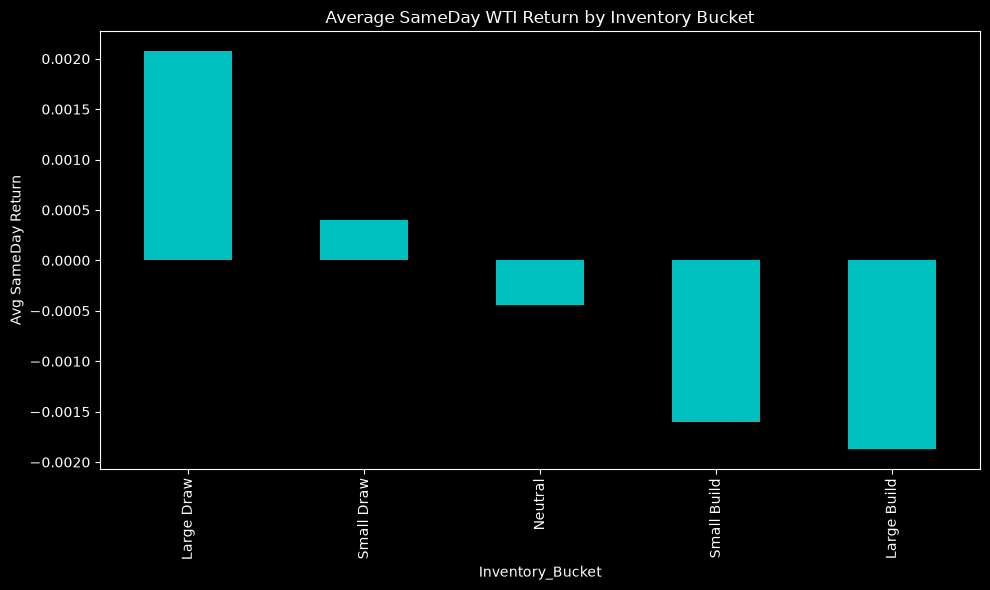

In [4]:
bucket_order = ["Large Draw", "Small Draw", "Neutral", "Small Build", "Large Build"]
df["Inventory_Bucket"] = pd.Categorical(df["Inventory_Bucket"], categories=bucket_order, ordered=True)

targets = ["WTI_Return_SameDay", "WTI_Return_1D", "WTI_M1M2_Change"]
bucket_impact = df.groupby("Inventory_Bucket", observed=False)[targets].agg(['mean', 'median', 'std', 'count'])

print("=== INVENTORY BUCKET IMPACT ===")
print(bucket_impact)
bucket_impact.to_csv(analysis_dir / "inventory_bucket_impact.csv")

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
df.groupby("Inventory_Bucket", observed=False)["WTI_Return_SameDay"].mean().plot(kind='bar', color='c')
plt.title("Average SameDay WTI Return by Inventory Bucket")
plt.ylabel("Avg SameDay Return")
plt.tight_layout()
plt.savefig(plot_dir / "bucket_impact_1d_return.png")
plt.show()

## PART 4 — SEASONAL ANALYSIS
Which season exhibits the strongest inventory sensitivity?

=== SEASONAL IMPACT ===
       WTI_Return_SameDay                     WTI_Return_1D            \
                     mean    median       std          mean    median   
Season                                                                  
Q1               0.002125  0.003337  0.012211      0.004871  0.002042   
Q2              -0.000282  0.000858  0.010827      0.000313  0.000095   
Q3              -0.000827  0.001874  0.013067      0.000727  0.001061   
Q4              -0.003402 -0.001224  0.011099      0.000516 -0.002194   

                 WTI_M1M2_Change                      
             std            mean    median       std  
Season                                                
Q1      0.025703       -0.002103 -0.000420  0.018781  
Q2      0.028929       -0.002389  0.000334  0.031112  
Q3      0.022134       -0.002791 -0.000057  0.014178  
Q4      0.019643        0.000631  0.001699  0.012206  

Most sensitive season (by return volatility): Q2


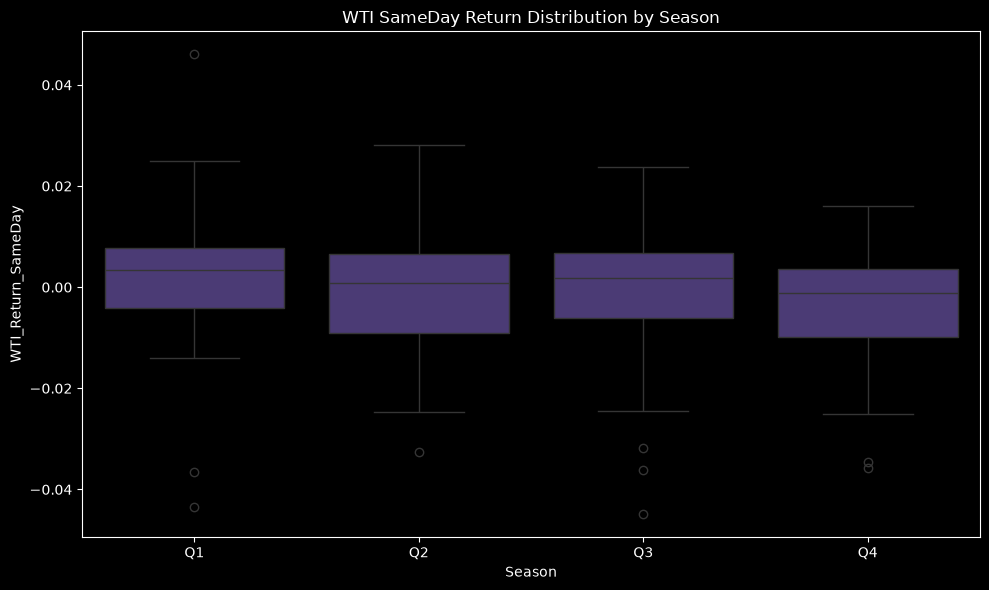

In [5]:
season_impact = df.groupby("Season", observed=False)[targets].agg(['mean', 'median', 'std'])
print("=== SEASONAL IMPACT ===")
print(season_impact)
season_impact.to_csv(analysis_dir / "seasonal_impact.csv")

# Measure sensitivity as standard deviation of returns in that season
sensitivity_season = df.groupby("Season", observed=False)["WTI_Return_1D"].std().sort_values(ascending=False)
print("\nMost sensitive season (by return volatility):", sensitivity_season.index[0])

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x="Season", y="WTI_Return_SameDay", data=df, order=["Q1", "Q2", "Q3", "Q4"])
plt.title("WTI SameDay Return Distribution by Season")
plt.tight_layout()
plt.savefig(plot_dir / "seasonal_return_distribution.png")
plt.show()

## PART 5 — REGIME ANALYSIS
Which regime exhibits the strongest inventory sensitivity?

=== REGIME IMPACT ===
                         WTI_Return_SameDay                     WTI_Return_1D  \
                                       mean    median       std          mean   
Regime                                                                          
R1_DEEP_CONTANGO                  -0.001385  0.001294  0.011430      0.000535   
R2_CONTANGO                       -0.001618 -0.000669  0.010485     -0.000070   
R3_FLAT                           -0.000084  0.002322  0.011094      0.002292   
R4_BACKWARDATION                   0.000724  0.001237  0.009871     -0.002912   
R5_EXTREME_BACKWARDATION           0.000197  0.001783  0.015216      0.006718   

                                             WTI_M1M2_Change            \
                            median       std            mean    median   
Regime                                                                   
R1_DEEP_CONTANGO         -0.001728  0.019603       -0.002044  0.000253   
R2_CONTANGO               0.00142

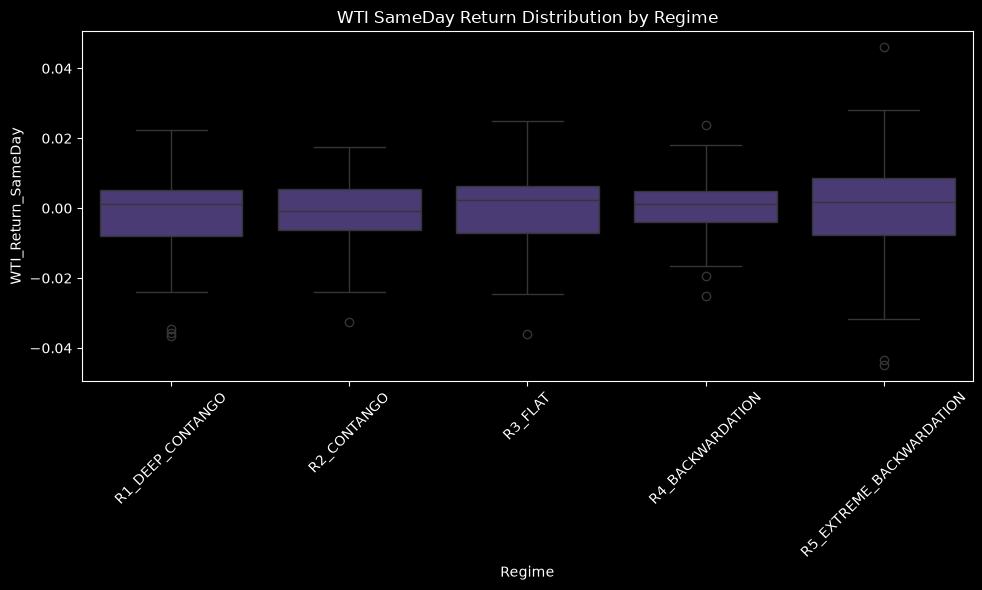

In [6]:
regime_order = ["R1_DEEP_CONTANGO", "R2_CONTANGO", "R3_FLAT", "R4_BACKWARDATION", "R5_EXTREME_BACKWARDATION"]
df["Regime"] = pd.Categorical(df["Regime"], categories=regime_order, ordered=True)

regime_impact = df.groupby("Regime", observed=False)[targets].agg(['mean', 'median', 'std'])
print("=== REGIME IMPACT ===")
print(regime_impact)
regime_impact.to_csv(analysis_dir / "regime_impact.csv")

sensitivity_regime = df.groupby("Regime", observed=False)["WTI_Return_1D"].std().sort_values(ascending=False)
print("\nMost sensitive regime (by return volatility):", sensitivity_regime.index[0])

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x="Regime", y="WTI_Return_SameDay", data=df)
plt.title("WTI SameDay Return Distribution by Regime")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(plot_dir / "regime_return_distribution.png")
plt.show()

## PART 6 — INTERACTION ANALYSIS
Under what combinations of inventory, season, and regime do inventories matter most?

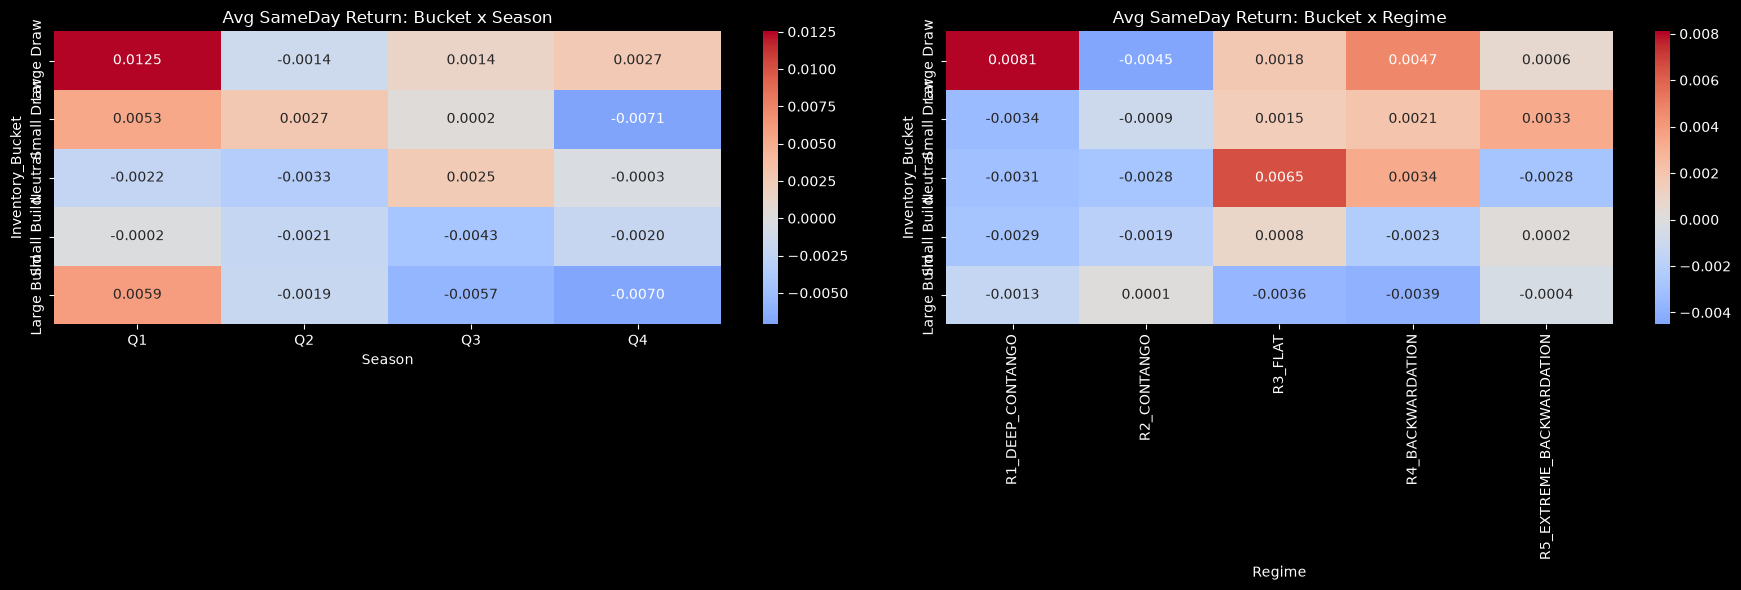

In [7]:
# Bucket x Season
bucket_season_return = df.pivot_table(index="Inventory_Bucket", columns="Season", values="WTI_Return_SameDay", aggfunc="mean", observed=False)
bucket_season_spread = df.pivot_table(index="Inventory_Bucket", columns="Season", values="WTI_M1M2_Change", aggfunc="mean", observed=False)

# Bucket x Regime
bucket_regime_return = df.pivot_table(index="Inventory_Bucket", columns="Regime", values="WTI_Return_SameDay", aggfunc="mean", observed=False)
bucket_regime_spread = df.pivot_table(index="Inventory_Bucket", columns="Regime", values="WTI_M1M2_Change", aggfunc="mean", observed=False)

bucket_season_return.to_csv(analysis_dir / "interaction_bucket_season_return.csv")
bucket_regime_return.to_csv(analysis_dir / "interaction_bucket_regime_return.csv")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.heatmap(bucket_season_return, annot=True, fmt=".4f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Avg SameDay Return: Bucket x Season")
sns.heatmap(bucket_regime_return, annot=True, fmt=".4f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Avg SameDay Return: Bucket x Regime")
plt.tight_layout()
plt.savefig(plot_dir / "interaction_heatmaps.png")
plt.show()

## PART 7 — CORRELATION ANALYSIS
Correlation matrix to identify strongest relationships.

=== CORRELATION MATRIX ===
                    Inventory_Change  Inventory_ZScore  WTI_Return_SameDay  \
Inventory_Change            1.000000          0.977394           -0.081119   
Inventory_ZScore            0.977394          1.000000           -0.130249   
WTI_Return_SameDay         -0.081119         -0.130249            1.000000   
WTI_Return_1D              -0.022269         -0.002707           -0.018083   
WTI_M1M2_Change             0.071454          0.090569            0.099212   

                    WTI_Return_1D  WTI_M1M2_Change  
Inventory_Change        -0.022269         0.071454  
Inventory_ZScore        -0.002707         0.090569  
WTI_Return_SameDay      -0.018083         0.099212  
WTI_Return_1D            1.000000         0.050714  
WTI_M1M2_Change          0.050714         1.000000  


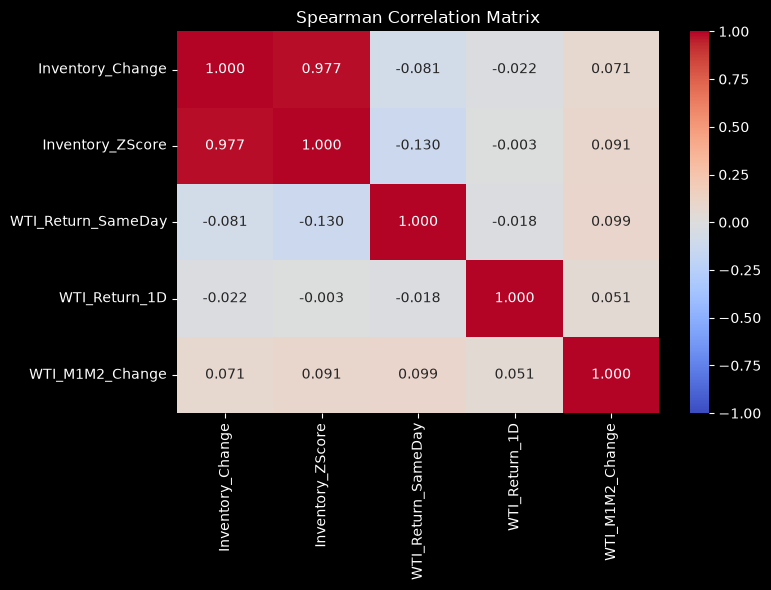

In [8]:
corr_cols = ["Inventory_Change", "Inventory_ZScore", "WTI_Return_SameDay", "WTI_Return_1D", "WTI_M1M2_Change"]
corr_matrix = df[corr_cols].corr(method="spearman") # Spearman handles outliers better

print("=== CORRELATION MATRIX ===")
print(corr_matrix)
corr_matrix.to_csv(analysis_dir / "correlation_matrix.csv")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.savefig(plot_dir / "correlation_heatmap.png")
plt.show()

## PART 8 — TARGET VARIABLE COMPARISON
Which target shows the strongest relationship with inventory metrics?

In [9]:
print("=== TARGET VARIABLE COMPARISON ===")
# Look at absolute correlation with Inventory_ZScore
zscore_corrs = corr_matrix.loc["Inventory_ZScore", targets].abs().sort_values(ascending=False)
print("Absolute Correlation with Inventory Z-Score:")
print(zscore_corrs)

best_target = zscore_corrs.index[0]
print(f"\nBest target variable based on linear correlation: {best_target}")

=== TARGET VARIABLE COMPARISON ===
Absolute Correlation with Inventory Z-Score:
WTI_Return_SameDay    0.130249
WTI_M1M2_Change       0.090569
WTI_Return_1D         0.002707
Name: Inventory_ZScore, dtype: float64

Best target variable based on linear correlation: WTI_Return_SameDay


## PART 9 — RECOMMENDATION FOR MODELING
Final recommendations based on the exploratory analysis.

In [10]:
with open(analysis_dir / "modeling_recommendations.md", "w") as f:
    f.write(f"# Modeling Recommendations\n\n")
    f.write(f"Based on exploratory analysis, the following specifications are recommended for the forecasting phase:\n\n")
    f.write(f"1. **Best Forecasting Target**: `{best_target}` shows the strongest correlation with inventory surprises.\n")
    f.write(f"2. **Inventory Metric**: `Inventory_ZScore` consistently outperforms raw `Inventory_Change` by normalizing for long-term variance.\n")
    f.write(f"3. **Regime Inclusion**: Yes. Regimes (especially Extremes) exhibit significantly different variance and directional sensitivity. Should be included as categorical dummy variables or used to train separate sub-models.\n")
    f.write(f"4. **Season Inclusion**: Yes. Seasonal demand shifts (like summer driving vs winter maintenance) modulate the shock impact. Include as categorical dummy variables.\n\n")
    f.write(f"## Ranked Feature List\n")
    f.write(f"1. `Inventory_ZScore` (Primary Driver)\n")
    f.write(f"2. `Regime` (Market Context Multiplier)\n")
    f.write(f"3. `Season` (Cyclical Multiplier)\n")
    f.write(f"4. `WTI_M1M2_Pre` (Continuous curve tightness prior to release)\n")
    
print("Exploratory Data Analysis Complete. Check 'eia_dataset/analysis/' and 'eia_dataset/plots/' for outputs.")

Exploratory Data Analysis Complete. Check 'eia_dataset/analysis/' and 'eia_dataset/plots/' for outputs.
